# Лабораторная работа 1. Описательная статистика: среднее, дисперсия, выбросы, корреляция

**Сюжет.** Мы сами генерируем 10 000 заказов интернет-магазина (цена товара, количество, скидка, доставка),
считаем из них итоговые суммы и потом изучаем получившиеся данные так, как аналитик изучал бы настоящие:

1. генерация данных;
2. выборочное среднее и дисперсия, посчитанные **руками**, без готовых функций;
3. стандартное отклонение и поиск выбросов по правилу трёх сигм;
4. ковариация и корреляция Пирсона, тоже руками;
5. графики: точечные, гистограммы, тепловая карта корреляций;
6. выводы.

> Это **готовый** ноутбук для учителя. Над каждой ячейкой: *Что делаем / Зачем / Как рассказать*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Генерация данных

### 1.1. Сырые случайные величины

**Что делаем.** Генерируем четыре «первичных» признака заказа. Берём с запасом 15 000 штук, почему — увидим в 1.2.

| признак | смысл | распределение | почему такое |
|---|---|---|---|
| `unit_price` | цена одного товара | экспоненциальное, `scale=40` | дешёвых товаров много, дорогих мало, длинный «хвост» вправо |
| `qty` | сколько штук в заказе | Пуассона, `lam=2` | целое число «событий», в среднем 2 |
| `discount` | скидка, доля от 0 до 0.35 | равномерное | любая скидка от 0 до 35 % одинаково вероятна |
| `delivery_fee` | цена доставки | равномерное от 0 до 25 | любая цена в диапазоне одинаково вероятна |

**Зачем `np.random.seed(42)`.** Компьютер выдаёт *псевдо*случайные числа по формуле от стартового числа (seed).
Один и тот же seed даёт одни и те же числа, значит результаты воспроизводимы: у Павла, у меня и у преподавателя таблицы совпадут.

**Как рассказать.** «Каждый заказ это набор случайных величин. Я выбрал для каждой распределение, которое
похоже на жизнь: цены скошены вправо, количество целое, скидка и доставка равномерные. seed фиксирует случайность,
чтобы результат можно было повторить».

In [2]:
np.random.seed(42)

n = 10000
size_buffer = int(n * 1.5)

unit_price_all = np.random.exponential(scale=40, size=size_buffer)
qty_all = np.random.poisson(lam=2, size=size_buffer)
discount_all = np.random.uniform(0, 0.35, size=size_buffer)
delivery_fee_all = np.random.uniform(0, 25, size=size_buffer)

print(unit_price_all[:5])
print(qty_all[:10])
print(discount_all[:5])
print(delivery_fee_all[:5])

[ 18.7707236  120.40485724  52.66982774  36.51770215   6.78499482]
[3 1 2 1 2 4 3 1 3 3]
[0.14665208 0.18417654 0.15207014 0.01298041 0.23824469]
[16.08522722  6.33262178 10.56114227 23.80996449 13.8090713 ]


### 1.2. Убираем заказы с нулём товаров

**Что делаем.** Пуассон иногда выдаёт `qty = 0`, а заказ из нуля товаров бессмыслен. Строим **булеву маску**
`qty_all > 0` (массив из True/False) и оставляем только строки, где True. Потом берём первые `n` штук.

**Зачем был запас 1.5·n.** Вероятность нуля у Пуассона с λ=2 равна $e^{-2} \approx 0.135$, то есть выкинем около 13.5 %.
Из 15 000 останется около 12 970, этого с запасом хватает на 10 000.

**Как рассказать.** «Маска это фильтр: массив True/False той же длины. Подставляем её в квадратные скобки, и NumPy
оставляет только элементы, где True. Одну и ту же маску применяю ко всем четырём массивам, чтобы строки не перепутались».

In [3]:
mask = qty_all > 0
print("доля qty > 0:", mask.sum() / len(mask))

unit_price = unit_price_all[mask][:n]
qty = qty_all[mask][:n]
discount = discount_all[mask][:n]
delivery_fee = delivery_fee_all[mask][:n]

print(len(unit_price), qty.min())

доля qty > 0: 0.8670666666666667
10000 1


### 1.3. Производные поля

**Что делаем.** Считаем из первичных признаков итоговые суммы заказа. Операции **поэлементные**: NumPy умножает
массивы по индексам без цикла.

$$subtotal = unit\_price \cdot qty, \qquad discount\_value = subtotal \cdot discount$$
$$order\_total = subtotal - discount\_value + delivery\_fee, \qquad avg\_item\_cost = subtotal / qty = unit\_price$$

**Как рассказать.** «Первые четыре столбца случайные, остальные четыре вычислены из них по формулам. Поэтому
вычисленные столбцы будут сильно коррелировать с исходными, это мы и увидим в пункте 4. `avg_item_cost`
в точности совпадает с `unit_price`, потому что в заказе все товары одной цены».

In [4]:
subtotal = unit_price * qty
discount_value = subtotal * discount
avg_item_cost = subtotal / qty
order_total = subtotal - discount_value + delivery_fee

### 1.4. Собираем таблицу

**Что делаем.** Складываем восемь массивов в `pandas.DataFrame`: это таблица, где строка это заказ, а столбец это признак.

**Как рассказать.** «DataFrame это Excel внутри Python. Ключ словаря становится названием столбца, массив становится его значениями».

In [5]:
df = pd.DataFrame({
    "unit_price": unit_price,
    "qty": qty,
    "discount": discount,
    "delivery_fee": delivery_fee,
    "subtotal": subtotal,
    "discount_value": discount_value,
    "avg_item_cost": avg_item_cost,
    "order_total": order_total,
})
df

,unit_price,qty,discount,delivery_fee,subtotal,discount_value,avg_item_cost,order_total
0,18.770724,3,0.146652,16.085227,56.312171,8.258297,18.770724,64.139101
1,120.404857,1,0.184177,6.332622,120.404857,22.175750,120.404857,104.561729
2,52.669828,2,0.152070,10.561142,105.339655,16.019016,52.669828,99.881782
3,36.517702,1,0.012980,23.809964,36.517702,0.474015,36.517702,59.853652
4,6.784995,2,0.238245,13.809071,13.569990,3.232978,6.784995,24.146083
...,...,...,...,...,...,...,...,...
9995,49.260247,1,0.030007,14.094971,49.260247,1.478150,49.260247,61.877068
9996,71.532696,2,0.069732,10.347412,143.065393,9.976223,71.532696,143.436582
9997,5.182083,2,0.307203,13.086292,10.364167,3.183905,5.182083,20.266554
9998,23.958846,1,0.031151,12.689414,23.958846,0.746340,23.958846,35.901920


## 2. Выборочное среднее и дисперсия (вручную)

**Что делаем.** Пишем свои функции вместо готовых `np.mean` / `np.var`.

$$\bar x = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad\qquad s^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar x)^2$$

**Зачем.** Среднее это оценка *математического ожидания* (центр распределения). Дисперсия это оценка того,
насколько сильно значения разбросаны вокруг центра. Делим на $n-1$, а не на $n$, чтобы оценка была
**несмещённой** (поправка Бесселя): мы меряем отклонения от $\bar x$, который сам подогнан под эти же данные,
поэтому они получаются чуть меньше настоящих, и $n-1$ это компенсирует.

**Как рассказать.** «Среднее: сложили всё и поделили на количество. Дисперсия: средний квадрат отклонения от среднего.
Квадрат нужен, чтобы плюсы и минусы не сократились. Делю на n−1, потому что это несмещённая оценка».

In [6]:
def sample_mean(arr):
    return sum(arr) / len(arr)


def sample_var(arr):
    mean_val = sample_mean(arr)
    ss = sum((x - mean_val) ** 2 for x in arr)
    return ss / (len(arr) - 1)


stats = pd.DataFrame({
    "mean": [sample_mean(df[col]) for col in df.columns],
    "variance": [sample_var(df[col]) for col in df.columns],
}, index=df.columns)
stats

,mean,variance
unit_price,39.465474,1528.525933
qty,2.312800,1.620718
discount,0.174812,0.010097
delivery_fee,12.595275,51.925966
subtotal,91.611731,13131.724644
discount_value,15.915377,590.046011
avg_item_cost,39.465474,1528.525933
order_total,88.291630,9333.358309


**Проверка (только для себя, в отчёт не включаем).** По правилам лабы готовые статистические функции запрещены,
поэтому `df.mean()` / `df.var()` здесь используем лишь чтобы убедиться, что наши функции правильные.
`ddof=1` означает «делить на n−1». Разница должна быть около нуля.

**Как рассказать.** «Свои функции я проверил библиотечными: совпадает до ошибок округления».

In [7]:
stats["np_mean"] = df.mean().values
stats["np_var"] = df.var(ddof=1).values
stats

,mean,variance,np_mean,np_var
unit_price,39.465474,1528.525933,39.465474,1528.525933
qty,2.312800,1.620718,2.312800,1.620718
discount,0.174812,0.010097,0.174812,0.010097
delivery_fee,12.595275,51.925966,12.595275,51.925966
subtotal,91.611731,13131.724644,91.611731,13131.724644
discount_value,15.915377,590.046011,15.915377,590.046011
avg_item_cost,39.465474,1528.525933,39.465474,1528.525933
order_total,88.291630,9333.358309,88.291630,9333.358309


**Сравнение с теорией (бонус).** Для исходных признаков мы знаем распределения, значит знаем истинные $E$ и $D$:

| признак | $E$ | $D$ |
|---|---|---|
| экспоненциальное, масштаб β=40 | β = 40 | β² = 1600 |
| равномерное на [a, b] | (a+b)/2 | (b−a)²/12 |
| Пуассон λ=2 **без нулей** | $\mu=\frac{\lambda}{1-e^{-\lambda}} \approx 2.31$ | $\mu(1+\lambda-\mu) \approx 1.59$ |

У обычного Пуассона $E = D = \lambda = 2$, но мы выкинули нули, поэтому среднее выросло, а разброс уменьшился.

**Как рассказать.** «Выборочные оценки близки к теоретическим, но не равны: выборка конечная. Чем больше n, тем ближе (закон больших чисел)».

In [8]:
lam = 2
mu_qty = lam / (1 - np.exp(-lam))

theory = pd.DataFrame({
    "E_theory": [40, mu_qty, 0.35 / 2, 25 / 2],
    "D_theory": [40 ** 2, mu_qty * (1 + lam - mu_qty), 0.35 ** 2 / 12, 25 ** 2 / 12],
}, index=["unit_price", "qty", "discount", "delivery_fee"])
theory.join(stats[["mean", "variance"]])

,E_theory,D_theory,mean,variance
unit_price,40.000000,1600.000000,39.465474,1528.525933
qty,2.313035,1.588974,2.312800,1.620718
discount,0.175000,0.010208,0.174812,0.010097
delivery_fee,12.500000,52.083333,12.595275,51.925966


## 3. Стандартное отклонение и выбросы по правилу трёх сигм

**Что делаем.** $s = \sqrt{s^2}$, это разброс в тех же единицах, что и данные (рубли, штуки).
**Выброс** по правилу 3σ это точка, у которой $|x - \bar x| > 3s$.

**Зачем.** Для *нормального* распределения в $\bar x \pm 3s$ лежит 99.7 % точек, вне его всего 0.3 %, то есть
около 30 точек из 10 000. Наши данные не нормальные, поэтому результат будет другим:

* равномерное распределение вообще не выходит за ±1.73σ, выбросов **0**;
* экспоненциальное с длинным хвостом: $P(X > \mu + 3\sigma) = e^{-4} \approx 1.8\%$, около **180** «выбросов».
  Это не ошибки данных, а свойство распределения.

**Как рассказать.** «Сигма это корень из дисперсии. Всё, что дальше трёх сигм от среднего, считаем выбросом.
Правило придумано для нормального распределения; у скошенных данных оно ловит много нормальных, просто крупных заказов».

In [9]:
def sample_std(arr):
    return np.sqrt(sample_var(arr))


means = {col: sample_mean(df[col]) for col in df.columns}
stds = {col: sample_std(df[col]) for col in df.columns}

outlier_masks = {col: np.abs(df[col] - means[col]) > 3 * stds[col] for col in df.columns}

outliers = pd.DataFrame({
    "std": pd.Series(stds),
    "count": pd.Series({col: m.sum() for col, m in outlier_masks.items()}),
})
outliers["percent"] = 100 * outliers["count"] / len(df)
outliers

,std,count,percent
unit_price,39.096367,174,1.74
qty,1.273074,67,0.67
discount,0.100485,0,0.00
delivery_fee,7.205967,0,0.00
subtotal,114.593737,217,2.17
discount_value,24.290863,215,2.15
avg_item_cost,39.096367,174,1.74
order_total,96.609308,208,2.08


## 4. Ковариация и корреляция Пирсона (вручную)

$$cov(x, y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar x)(y_i - \bar y) \qquad\qquad r = \frac{cov(x,y)}{s_x \, s_y}$$

**Что делаем.** Считаем $r$ для каждой пары столбцов, получаем матрицу 8×8.

**Зачем.** Ковариация показывает, растут ли две величины вместе (плюс) или в разные стороны (минус), но её значение
зависит от единиц измерения. Делим на оба стандартных отклонения и получаем **корреляцию** $r \in [-1, 1]$:
1 означает идеальную прямую вверх, −1 прямую вниз, 0 отсутствие *линейной* связи.

**Как рассказать.** «Если x выше среднего и y выше среднего, произведение отклонений положительное. Если так почти
всегда, сумма большая и положительная, связь прямая. Корреляция это нормированная ковариация. На диагонали
единицы: признак полностью коррелирует сам с собой».

In [10]:
def sample_cov(x, y):
    mean_x = sample_mean(x)
    mean_y = sample_mean(y)
    return np.sum((x - mean_x) * (y - mean_y)) / (len(x) - 1)


columns = df.columns.tolist()
corr_matrix = np.zeros((len(columns), len(columns)))

for i, col1 in enumerate(columns):
    for j, col2 in enumerate(columns):
        corr_matrix[i, j] = sample_cov(df[col1], df[col2]) / (stds[col1] * stds[col2])

corr_df = pd.DataFrame(corr_matrix, index=columns, columns=columns)
corr_df.round(3)

,unit_price,qty,discount,delivery_fee,subtotal,discount_value,avg_item_cost,order_total
unit_price,1.000,0.007,-0.013,-0.013,0.786,0.628,1.000,0.774
qty,0.007,1.000,0.011,-0.008,0.443,0.360,0.007,0.435
discount,-0.013,0.011,1.000,-0.004,-0.009,0.371,-0.013,-0.104
delivery_fee,-0.013,-0.008,-0.004,1.000,-0.013,-0.012,-0.013,0.062
subtotal,0.786,0.443,-0.009,-0.013,1.000,0.794,0.786,0.985
discount_value,0.628,0.360,0.371,-0.012,0.794,1.000,0.628,0.690
avg_item_cost,1.000,0.007,-0.013,-0.013,0.786,0.628,1.000,0.774
order_total,0.774,0.435,-0.104,0.062,0.985,0.690,0.774,1.000


**Проверка** готовой функцией `df.corr()` (только для себя): максимальная разница должна быть около нуля.

In [11]:
np.abs(corr_df - df.corr()).max().max()

np.float64(3.3306690738754696e-15)

## 5. Точечные графики с выделением выбросов

**Что делаем.** Для каждого признака рисуем точки: по оси X номер заказа, по оси Y значение. Обычные точки синие,
выбросы (маски из пункта 3) красные. `plt.subplots(2, 4)` создаёт сетку из 8 графиков, `axes.flatten()`
превращает её в плоский список, чтобы идти по нему циклом.

**Как рассказать.** «Видно, что у цены и итоговых сумм красные точки сверху: это редкие дорогие заказы.
У скидки и доставки выбросов нет, точки ровной полосой: так выглядит равномерное распределение.
У qty точки ступеньками, потому что количество целое».

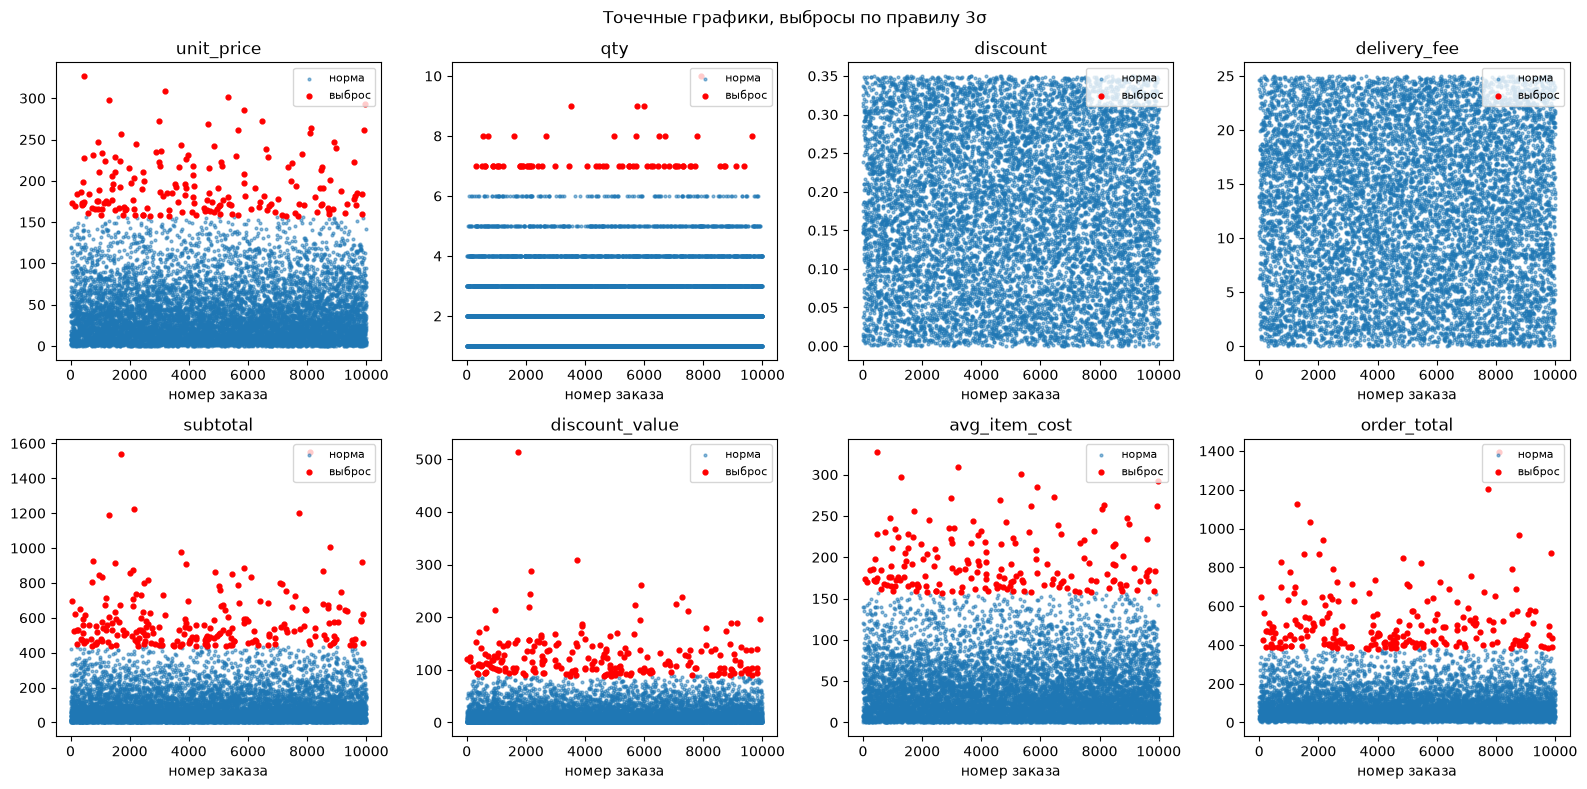

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
x = np.arange(len(df))

for ax, col in zip(axes, df.columns):
    m = outlier_masks[col].values
    ax.scatter(x[~m], df[col][~m], c="tab:blue", s=4, alpha=0.5, label="норма")
    ax.scatter(x[m], df[col][m], c="red", s=12, label="выброс")
    ax.set_title(col)
    ax.set_xlabel("номер заказа")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Точечные графики, выбросы по правилу 3σ")
plt.tight_layout()
plt.show()

## 6. Гистограммы распределений

### 6.1. Гистограммы с границей 3σ

**Что делаем.** Гистограмма делит диапазон значений на 50 «корзин» и показывает, сколько значений попало в каждую.
Это картинка формы распределения. Добавляем вертикальные линии: среднее и границу $\bar x + 3s$.

**Как рассказать.** «По форме видно, какое распределение мы закладывали: цена спадает экспонентой,
скидка и доставка плоские (равномерные), qty отдельные столбики в целых точках (Пуассон без нуля).
Итоговые суммы тоже скошены вправо, потому что они получены из цены».

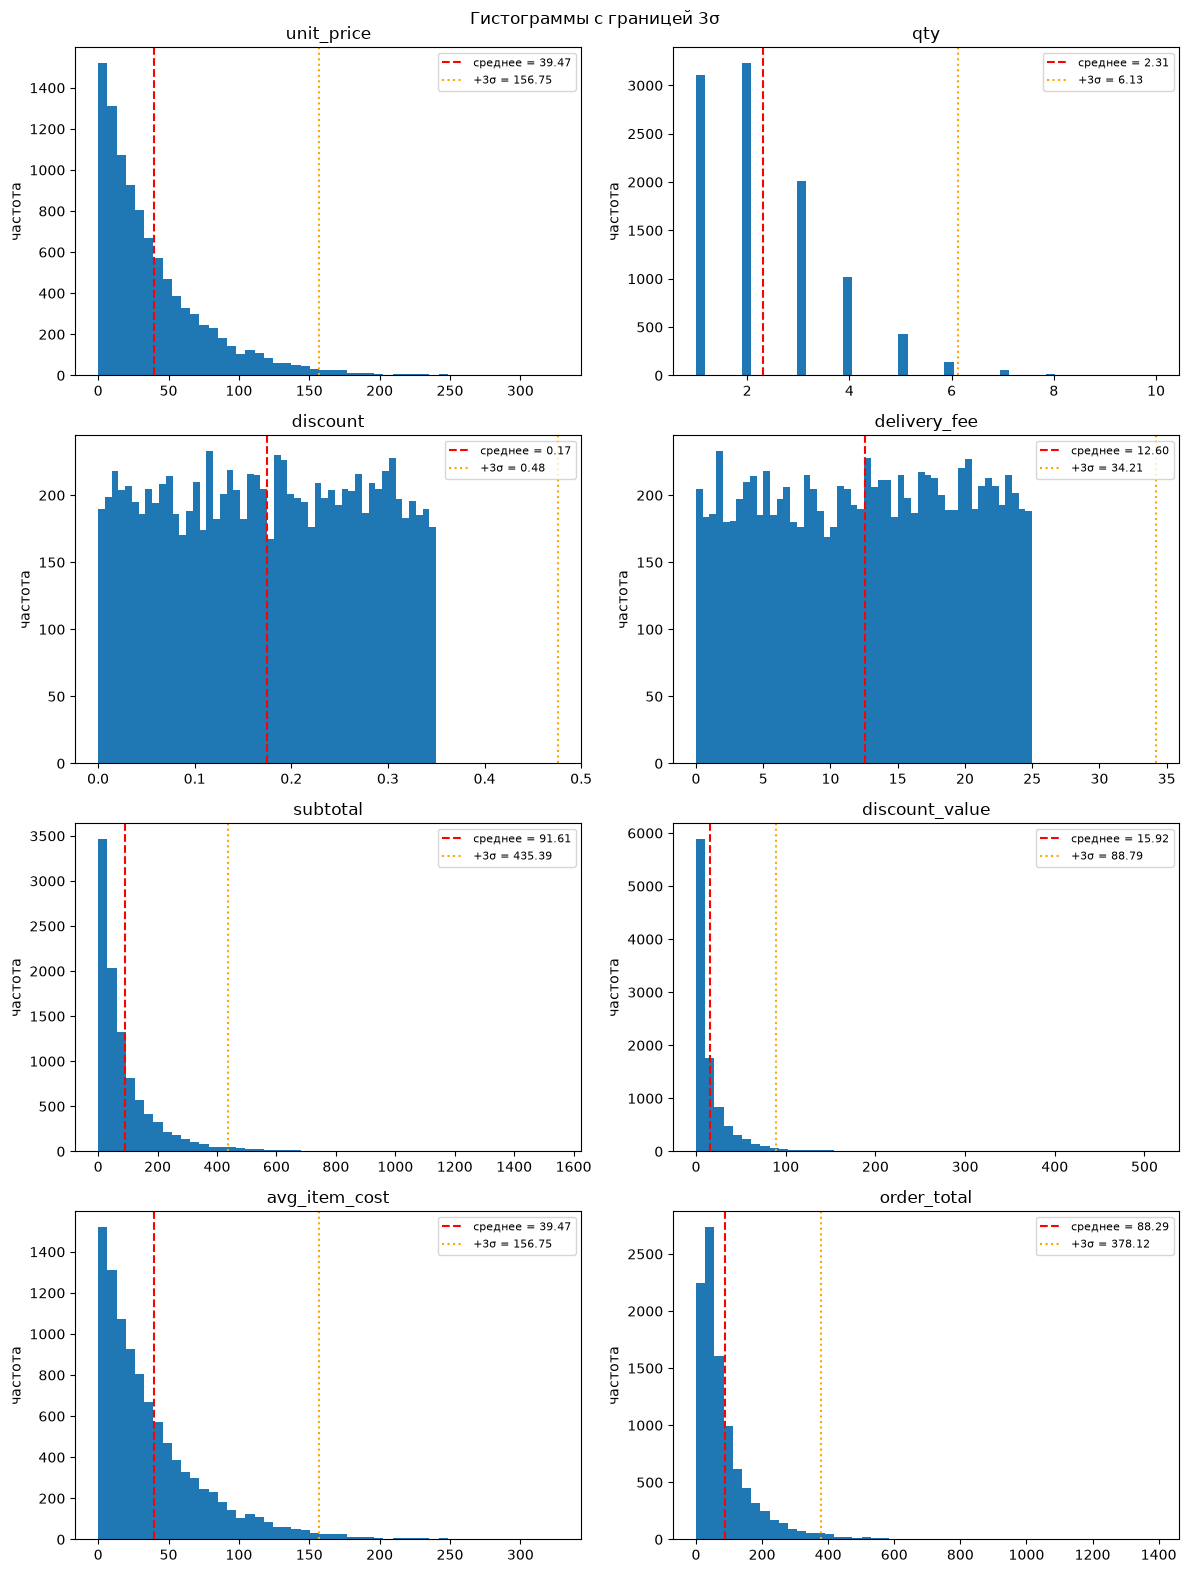

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.flatten()

for ax, col in zip(axes, df.columns):
    upper = means[col] + 3 * stds[col]
    ax.hist(df[col], bins=50, color="tab:blue")
    ax.axvline(means[col], color="red", linestyle="--", label=f"среднее = {means[col]:.2f}")
    ax.axvline(upper, color="orange", linestyle=":", label=f"+3σ = {upper:.2f}")
    ax.set_title(col)
    ax.set_ylabel("частота")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Гистограммы с границей 3σ")
plt.tight_layout()
plt.show()

### 6.2. Соответствует ли гистограмма заданному распределению?

**Что делаем.** Это отдельный пункт задания. Для четырёх исходных признаков рисуем гистограмму в режиме
`density=True` (высота столбика = доля / ширина корзины, площадь под гистограммой = 1) и поверх неё
**теоретическую** кривую плотности, посчитанную по формуле руками:

* экспоненциальное: $f(x) = \frac{1}{\beta} e^{-x/\beta}$, β = 40;
* равномерное на [a, b]: $f(x) = \frac{1}{b-a}$ (горизонтальная линия);
* Пуассон без нуля: $P(k) = \frac{\lambda^k e^{-\lambda}}{k!\,(1 - e^{-\lambda})}$, $k = 1, 2, \dots$
  (делим на $1-e^{-\lambda}$, потому что выкинули нули и вероятности остальных надо «перераспределить», чтобы сумма снова была 1).

Для `qty` значения целые, поэтому вместо гистограммы считаем долю каждого $k$ и ставим рядом теоретическую вероятность.

**Как рассказать.** «Если данные действительно из заданного распределения, теоретическая кривая ложится на
верхушки столбиков. Небольшие расхождения это случайность конечной выборки. Совпадает, значит генерация верная».

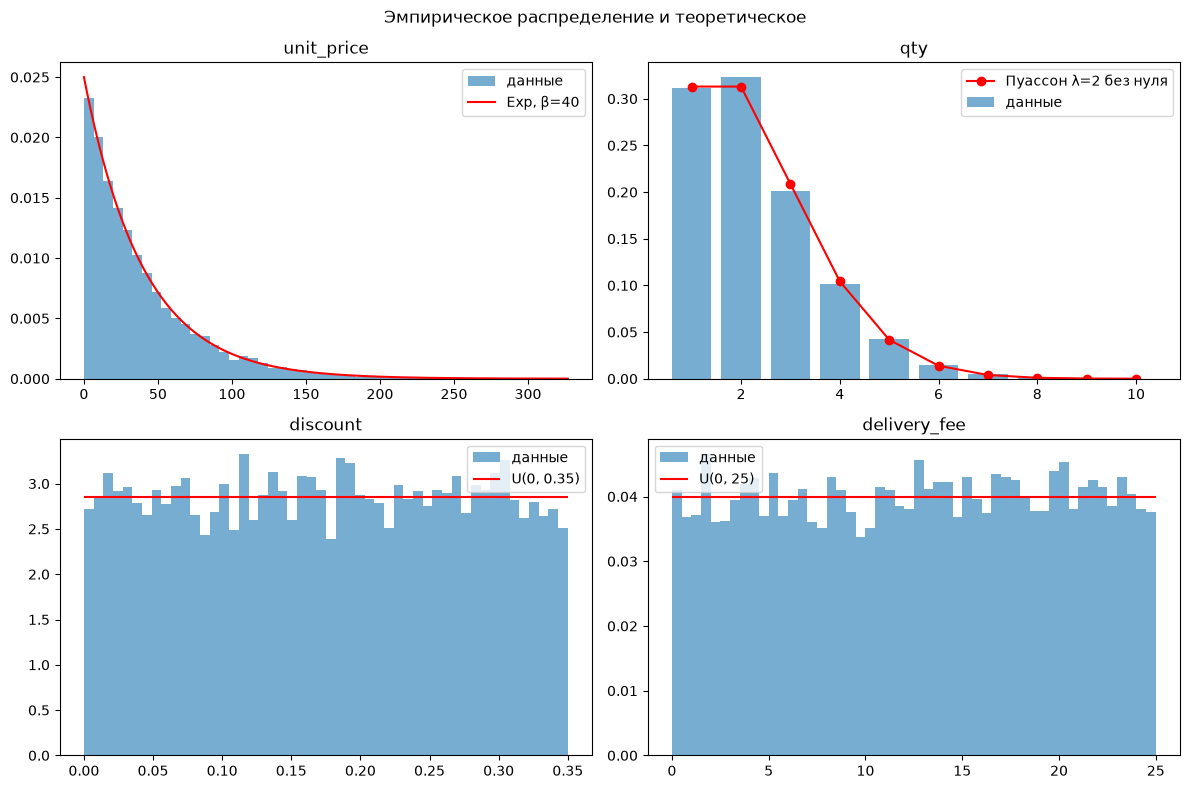

In [14]:
def factorial(k):
    result = 1
    for i in range(2, k + 1):
        result *= i
    return result


fig, axes = plt.subplots(2, 2, figsize=(12, 8))

grid = np.linspace(0, unit_price.max(), 300)
axes[0, 0].hist(unit_price, bins=50, density=True, alpha=0.6, label="данные")
axes[0, 0].plot(grid, np.exp(-grid / 40) / 40, color="red", label="Exp, β=40")
axes[0, 0].set_title("unit_price")

ks = np.arange(1, qty.max() + 1)
freq = np.array([(qty == k).sum() / len(qty) for k in ks])
pmf = np.array([lam ** k * np.exp(-lam) / factorial(k) for k in ks]) / (1 - np.exp(-lam))
axes[0, 1].bar(ks, freq, alpha=0.6, label="данные")
axes[0, 1].plot(ks, pmf, "o-", color="red", label="Пуассон λ=2 без нуля")
axes[0, 1].set_title("qty")

for ax, data, a, b, name in [(axes[1, 0], discount, 0, 0.35, "discount"),
                             (axes[1, 1], delivery_fee, 0, 25, "delivery_fee")]:
    ax.hist(data, bins=50, density=True, alpha=0.6, label="данные")
    ax.hlines(1 / (b - a), a, b, color="red", label=f"U({a}, {b})")
    ax.set_title(name)

for ax in axes.flatten():
    ax.legend()

plt.suptitle("Эмпирическое распределение и теоретическое")
plt.tight_layout()
plt.show()

## 7. Тепловая карта корреляций

**Что делаем.** Рисуем матрицу `corr_df` из пункта 4 цветом: красный это сильная положительная связь,
синий отрицательная, белый около нуля. `annot=True` пишет числа в клетках.

**Как рассказать.** «Сильные связи только там, где один признак *вычислен* из другого:
`unit_price` и `avg_item_cost` дают ровно 1, это один и тот же столбец; `subtotal`, `discount_value`,
`order_total` сильно связаны с ценой и между собой. Исходные случайные признаки между собой около 0,
потому что мы генерировали их независимо».

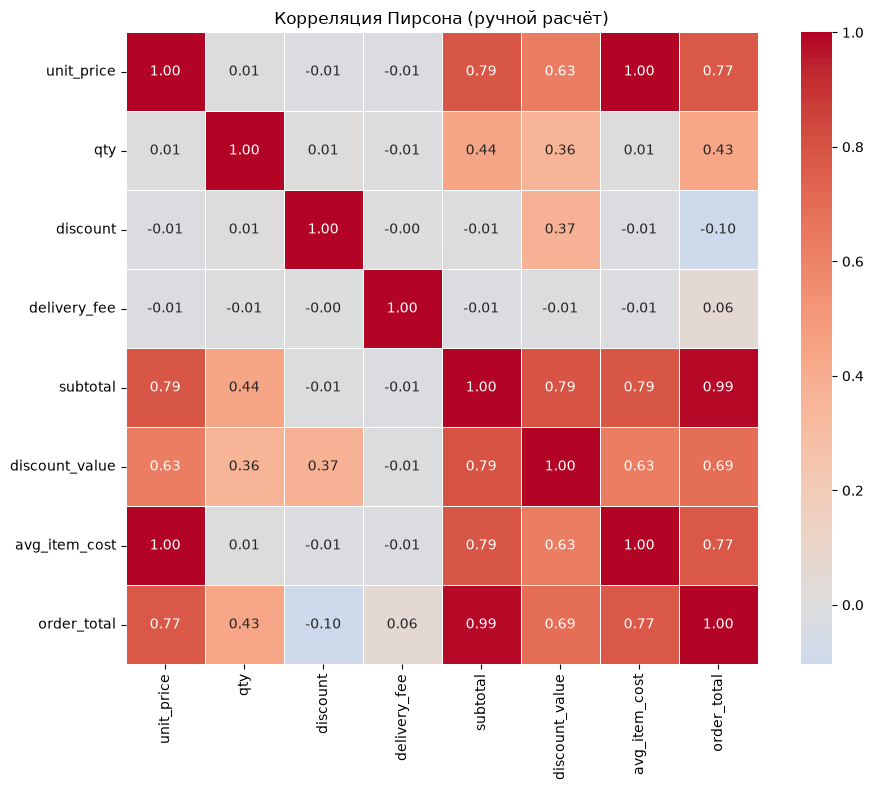

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Корреляция Пирсона (ручной расчёт)")
plt.tight_layout()
plt.show()

## 8. Выводы

1. Выборочные средние и дисперсии, посчитанные вручную, совпали с NumPy, а для исходных признаков близки к теоретическим $E$ и $D$.
2. Правило трёх сигм работает «как в учебнике» только для нормального распределения. У равномерных признаков выбросов нет,
   у экспоненциальной цены и всех сумм, построенных из неё, 1.7–2.2 % (вместо «нормальных» 0.3 %), у `qty` 0.7 %:
   это длинный правый хвост, а не ошибки.
3. Гистограммы исходных признаков совпали с теоретическими плотностями: данные сгенерированы из заданных распределений.
4. Сильная корреляция есть только между признаками, связанными формулой (`unit_price` и `avg_item_cost` = 1,
   `subtotal` и `order_total` около 0.99). Независимо сгенерированные признаки не коррелируют (r ≈ 0).
   `avg_item_cost` дублирует `unit_price`, для обучения модели один из них стоит удалить.
5. Корреляция ловит только *линейную* связь и не говорит о причине.